<a href="https://colab.research.google.com/github/henry09027/NTU-Course-MachineLearning/blob/main/Homework/HW1/Code%20/2026ML_HW1_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **2026 ML FALL HW1: PM2.5 Prediction (Regression)**

Author: MLTAs

Methods:
* Training with all data
* Optimizer: RMSProp (default)
* TODOs:
  - Complete the `valid()` function
  - Tune the hyperparameters in `train_config`
  - Implement 2nd-order polynomial regression model (without interaction terms) in `minibatch_2()`
  - Implement feature normalization in `normalize_train_data()`
  - Feature selection



# **Import Some Packages**

In [1]:
import numpy as np
import csv
import math
import pandas as pd
import os
import matplotlib.pyplot as plt
from argparse import Namespace
from google.colab import files

# **Fix random seed**


This is for the reproduction of your result. **DO NOT modify this secton!**


In [2]:
seed = 9487
np.random.seed(seed)

# **Download training data**


In [3]:
!gdown --id "1Hfzrcm69QwdFvdeF0uASoQlcVxKw_hHy" --output "train.csv"
!gdown --id '155N6fzI7vAFzHAGdy6jkaWIksWH6Y1G2' --output "test.csv"

# Incase the links above die, you can use the following instead.
#!gdown --id '11abE854Eyv4BA7qt5k8r_80sJ3KuOQUN' --output "train.csv"
#!gdown --id '1uod-Z4ztluXnuHtgUbm39nMudUKqXHMl' --output "test.csv"

# If the data is still missing, you can manually download it from kaggle, and upload the files under /content

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1Hfzrcm69QwdFvdeF0uASoQlcVxKw_hHy
To: /content/train.csv
100% 324k/324k [00:00<00:00, 37.1MB/s]
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=155N6fzI7vAFzHAGdy6jkaWIksWH6Y1G2
To: /content/test.csv
100% 49.0k/49.0k [00:00<00:00, 27.0MB/s]


In [4]:
test_df = pd.read_csv('test.csv')
train_df = pd.read_csv('train.csv')

print(f'Test Dataframe')
display(test_df)
files.download('test.csv')

print(f'Train Dataframe')
display(train_df)
files.download('train.csv')

Test Dataframe


,AMB_TEMP,CO,NO,NO2,NOx,O3,PM10,WS_HR,RAINFALL,RH,SO2,WD_HR,WIND_DIREC,WIND_SPEED,PM2.5
0,27.5,0.22,0.7,9.0,9.8,13.2,31.0,1.2,0.0,79.0,1.7,180.0,171.0,1.2,20.0
1,27.2,0.17,0.4,5.0,5.4,15.7,20.0,1.5,0.0,79.0,1.6,192.0,187.0,1.9,8.0
2,26.8,0.17,0.4,4.3,4.8,12.8,16.0,1.6,0.0,81.0,1.3,181.0,180.0,1.8,9.0
3,26.7,0.19,0.4,4.1,4.5,12.0,21.0,1.7,0.0,80.0,1.5,179.0,188.0,2.3,6.0
4,26.4,0.22,0.4,4.1,4.6,10.1,23.0,2.2,0.0,81.0,1.5,184.0,186.0,1.9,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,16.0,0.26,0.3,3.9,4.2,47.1,34.0,2.7,0.0,70.0,0.5,130.0,133.0,2.8,13.0
716,15.6,0.25,0.4,3.3,3.7,44.1,27.0,3.0,0.0,74.0,0.6,136.0,131.0,3.2,15.0
717,15.7,0.24,0.4,3.7,4.1,44.1,29.0,2.9,0.0,73.0,0.6,133.0,129.0,2.7,12.0
718,15.1,0.24,0.6,10.5,11.1,29.9,9.0,0.8,0.0,95.0,0.6,24.0,21.0,1.1,8.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Train Dataframe


,AMB_TEMP,CO,NO,NO2,NOx,O3,PM10,WS_HR,RAINFALL,RH,SO2,WD_HR,WIND_DIREC,WIND_SPEED,PM2.5
0,10.8,0.32,1.7,8.6,10.3,22.9,21,0.6,0.0,71,1.9,172,171,0.6,15
1,10.8,0.27,1.6,6.2,7.8,23.8,20,1.4,0.0,71,1.7,161,129,1.8,13
2,11.0,0.25,0.9,5.4,6.3,27.4,21,0.8,0.0,68,1.6,152,147,1.5,12
3,11.0,0.23,0.7,3.1,3.8,29.5,21,1.8,0.0,68,1.6,138,145,1.7,9
4,11.3,0.22,0.8,2.9,3.8,30.7,16,1.9,0.0,67,1.6,140,139,1.7,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5769,29.0,0.41,1.2,14.0,15.3,23.0,21,1.4,0.0,74,2.8,149,168,2.0,14
5770,28.2,0.33,1.7,11.7,13.5,19.5,23,2.1,0.0,78,2.3,187,179,2.5,15
5771,28.0,0.29,1.3,9.1,10.4,17.6,17,1.5,0.0,78,2.0,173,200,1.5,13
5772,28.0,0.27,1.4,9.5,11.0,15.4,17,1.1,0.0,75,1.8,171,135,0.9,10


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Feature Statistics**

,raw_min,raw_max,n_invalid,pct_inv,p1,median,p99,clean_max,stuck_runs>=6h
AMB_TEMP,7.20,37.50,0,0.0,9.40,25.9,35.100,37.50,1.0
CO,0.04,1.54,0,0.0,0.09,0.3,0.900,1.54,0.0
NO,0.00,63.30,0,0.0,0.10,1.7,15.927,63.30,1.0
NO2,0.80,60.00,0,0.0,1.90,8.0,37.227,60.00,0.0
NOx,1.60,94.10,0,0.0,2.80,10.0,48.927,94.10,0.0
O3,1.60,131.40,0,0.0,3.10,29.3,88.454,131.40,0.0
PM10,0.00,239.00,0,0.0,2.00,20.0,73.270,239.00,0.0
WS_HR,0.00,6.10,0,0.0,0.20,1.3,3.800,6.10,1.0
RAINFALL,0.00,62.40,0,0.0,0.00,0.0,6.500,62.40,NaN
RH,33.00,96.00,0,0.0,45.00,75.5,92.000,96.00,12.0


Most frequent invalid codes per column: {}
NOx - (NO+NO2): median=0.00, |resid|>5ppb in 0.00% of rows
PM2.5 > PM10 in 3.27% of rows (> PM10+10: 0.00%)
Same check on test set:


,raw_min,raw_max,n_invalid,pct_inv
AMB_TEMP,12.70,30.00,0,0.0
CO,0.06,1.06,0,0.0
NO,0.10,35.20,0,0.0
NO2,0.80,29.80,0,0.0
NOx,1.40,60.70,0,0.0
O3,0.00,55.90,0,0.0
PM10,0.00,61.00,0,0.0
WS_HR,0.10,4.60,0,0.0
RAINFALL,0.00,10.50,0,0.0
RH,56.00,100.00,0,0.0


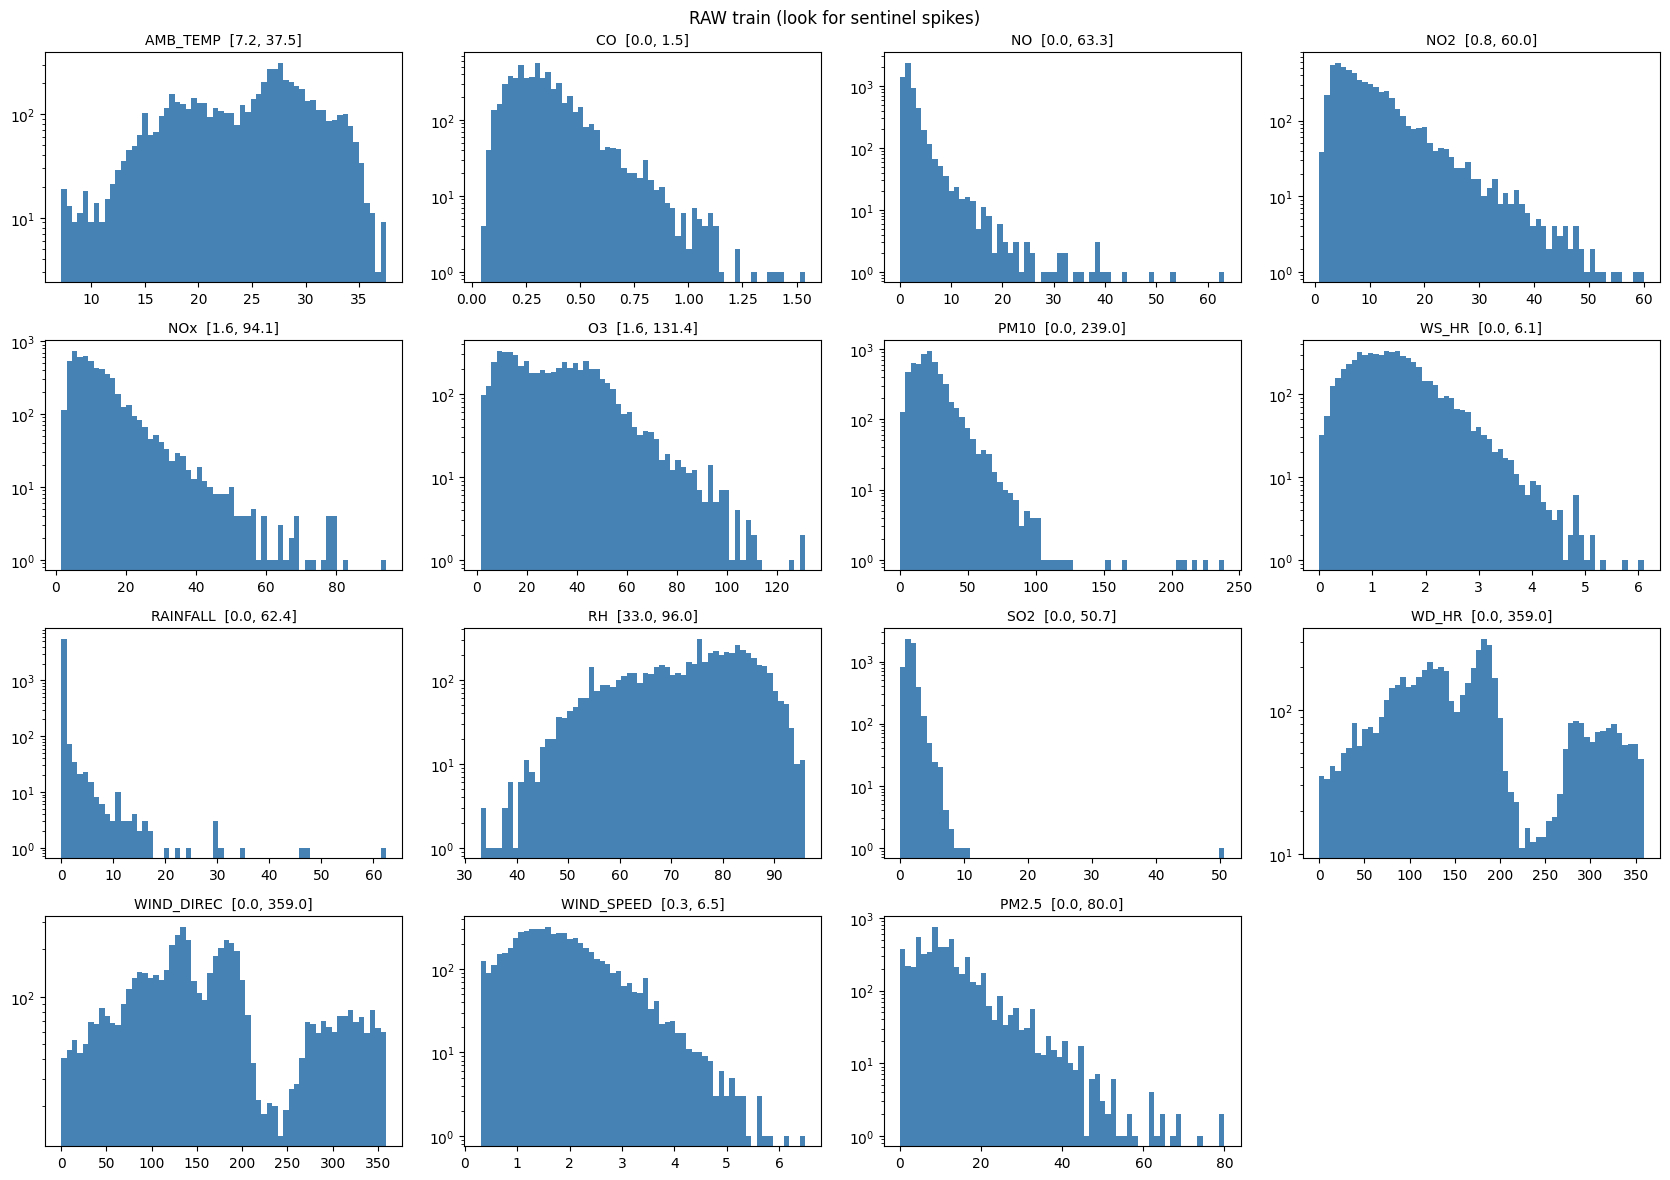

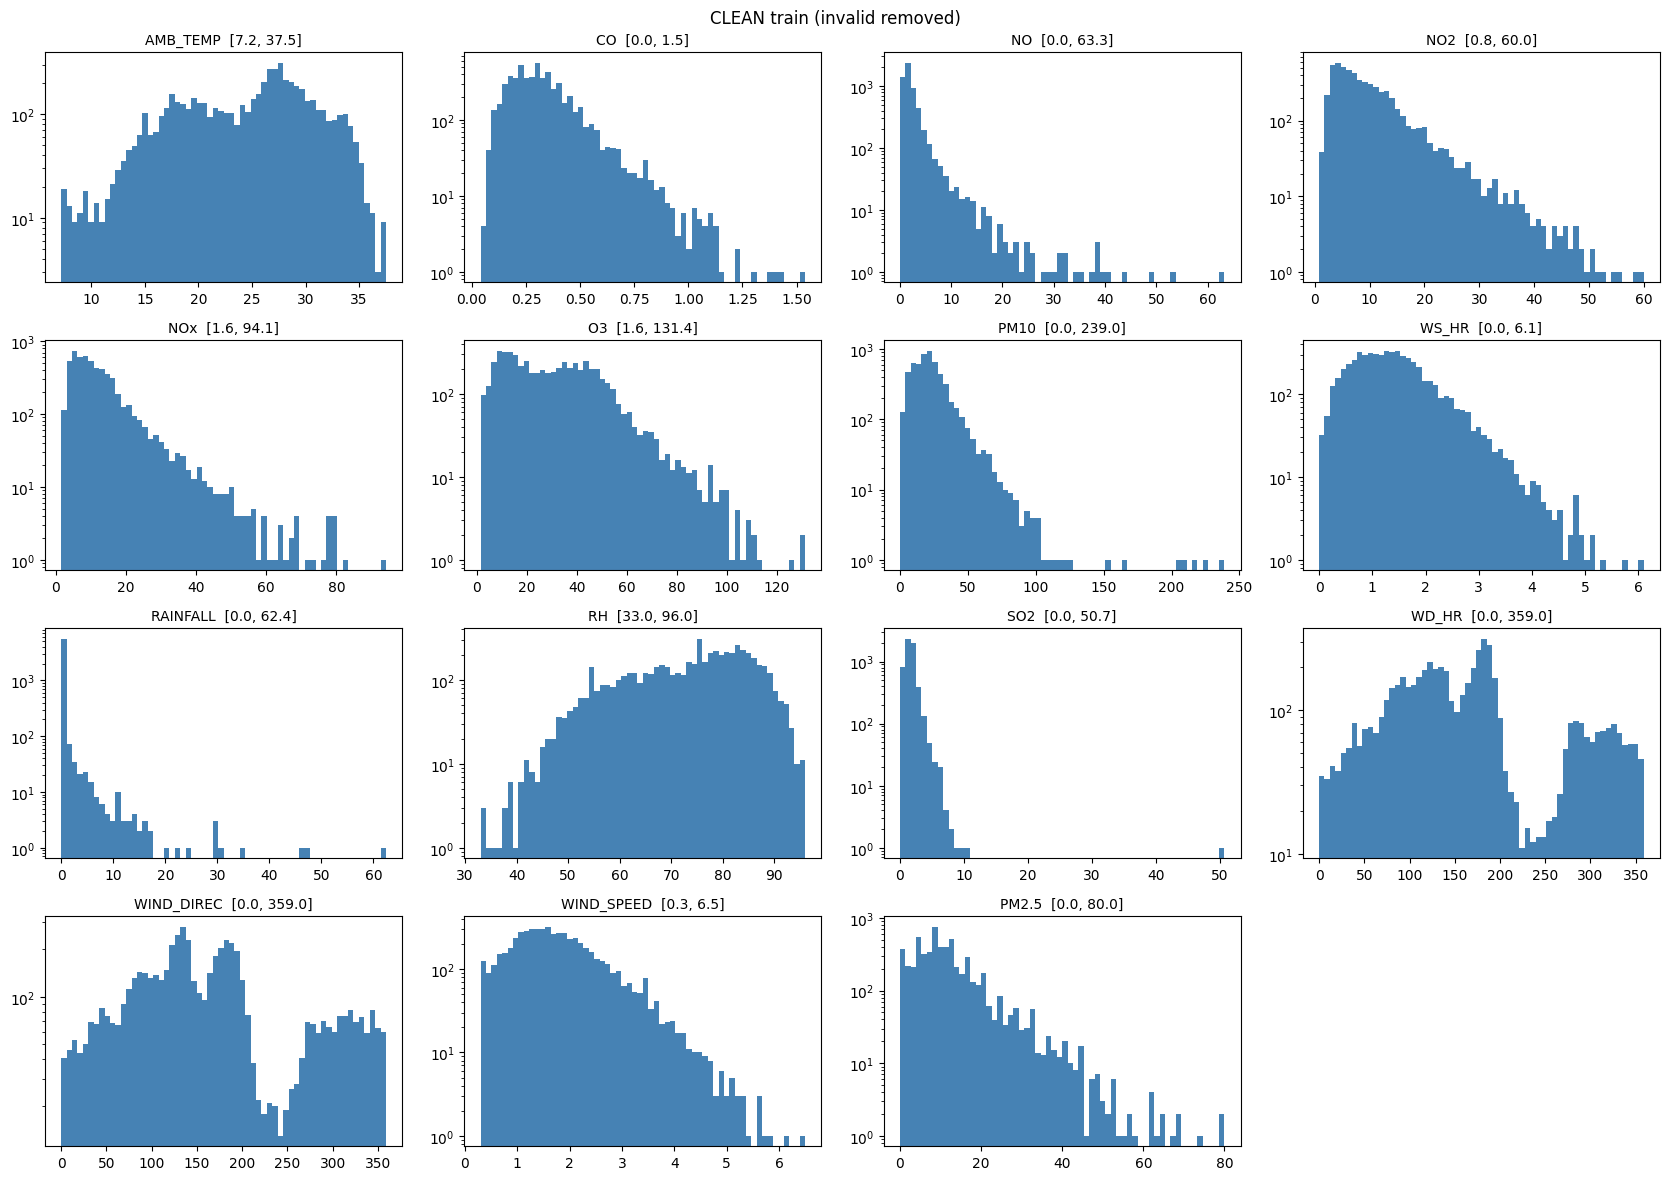

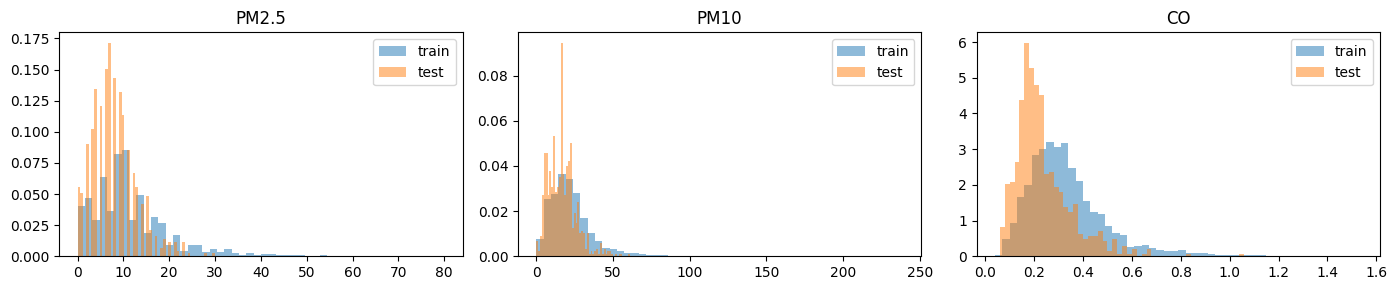

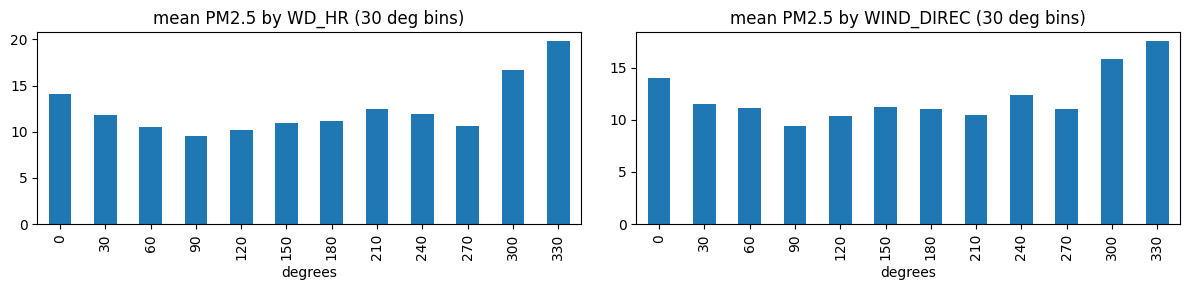

In [ ]:
TARGET = 'PM2.5'
COLS = list(train_df.columns)

# Physical / instrument plausibility bounds (inclusive). Anything outside is
# treated as a sensor error or missing-value code, NOT as a real observation.
# These are deliberately loose; the "modelling cap" on PM2.5 is a separate,
# testable choice (see FILTERS in section 3).
HARD_LIMITS = {
    'AMB_TEMP':   (-10, 45),    # deg C
    'CO':         (0, 20),      # ppm
    'NO':         (0, 500),     # ppb
    'NO2':        (0, 300),     # ppb
    'NOx':        (0, 800),     # ppb
    'O3':         (0, 300),     # ppb
    'PM10':       (0, 1000),    # ug/m3
    'WS_HR':      (0, 40),      # m/s
    'RAINFALL':   (0, 200),     # mm/hr
    'RH':         (0, 100),     # %
    'SO2':        (0, 100),     # ppb
    'WD_HR':      (0, 360),     # degrees
    'WIND_DIREC': (0, 360),     # degrees
    'WIND_SPEED': (0, 50),      # m/s
    'PM2.5':      (0, 500),     # ug/m3
}


def invalid_mask(df):
    """True where a value is NaN or outside HARD_LIMITS."""
    m = df.isna().copy()
    for c, (lo, hi) in HARD_LIMITS.items():
        if c in df.columns:
            m[c] |= (df[c] < lo) | (df[c] > hi)
    return m


def longest_constant_runs(s, min_len=6):
    """Number of runs where the value is identical for >= min_len hours."""
    grp = (s != s.shift()).cumsum()
    lens = s.groupby(grp).transform('size')
    return int(((lens >= min_len) & (grp != grp.shift())).sum())


# %% ------------------------------------------------- 1. Summary / sanity table
def eda_report(df):
    m = invalid_mask(df)
    clean = df.mask(m)
    rep = pd.DataFrame({
        'raw_min':   df.min(),
        'raw_max':   df.max(),
        'n_invalid': m.sum(),
        'pct_inv':   (100 * m.mean()).round(2),
        'p1':        clean.quantile(0.01),
        'median':    clean.median(),
        'p99':       clean.quantile(0.99),
        'clean_max': clean.max(),
        'stuck_runs>=6h': [longest_constant_runs(clean[c].dropna()) if c != 'RAINFALL' else np.nan
                           for c in df.columns],
    })
    # Most common raw values among invalid entries -> reveals sentinel codes (-1, 999, ...)
    codes = {c: df.loc[m[c], c].value_counts().head(3).to_dict() for c in df.columns if m[c].any()}
    return rep, codes


rep, codes = eda_report(train_df)
display(rep)
print('Most frequent invalid codes per column:', codes)

# Cross-variable consistency checks (report only)
c = train_df.mask(invalid_mask(train_df))
nox_resid = c['NOx'] - (c['NO'] + c['NO2'])
print(f"NOx - (NO+NO2): median={nox_resid.median():.2f}, |resid|>5ppb in "
      f"{(nox_resid.abs() > 5).mean()*100:.2f}% of rows")
print(f"PM2.5 > PM10 in {(c['PM2.5'] > c['PM10']).mean()*100:.2f}% of rows "
      f"(> PM10+10: {(c['PM2.5'] > c['PM10'] + 10).mean()*100:.2f}%)")
print("Same check on test set:")
display(eda_report(test_df)[0][['raw_min', 'raw_max', 'n_invalid', 'pct_inv']])


# %% ------------------------------------------------------------ 2. Histograms
def plot_hists(df, cols, clean=True, log_y=True, bins=60, title=''):
    d = df.mask(invalid_mask(df)) if clean else df
    ncol = 4
    nrow = int(np.ceil(len(cols) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.0 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        v = d[col].dropna()
        ax.hist(v, bins=bins, color='steelblue', edgecolor='none')
        if log_y:
            ax.set_yscale('log')          # tails / rare spikes become visible
        ax.set_title(f'{col}  [{v.min():.1f}, {v.max():.1f}]', fontsize=10)
    for ax in axes[len(cols):]:
        ax.axis('off')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_hists(train_df, COLS, clean=False, title='RAW train (look for sentinel spikes)')
plot_hists(train_df, COLS, clean=True,  title='CLEAN train (invalid removed)')

# Train vs test distribution of the target-related columns
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for ax, col in zip(axes, ['PM2.5', 'PM10', 'CO']):
    for name, d in [('train', train_df), ('test', test_df)]:
        v = d[col].mask(invalid_mask(d)[col]).dropna()
        ax.hist(v, bins=50, density=True, alpha=0.5, label=name)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

# Wind direction: why raw degrees are a bad linear feature
d = train_df.mask(invalid_mask(train_df))
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, col in zip(axes, ['WD_HR', 'WIND_DIREC']):
    bins30 = (d[col] // 30 * 30)
    d.groupby(bins30)[TARGET].mean().plot.bar(ax=ax)
    ax.set_title(f'mean PM2.5 by {col} (30 deg bins)'); ax.set_xlabel('degrees')
plt.tight_layout(); plt.show()

In [ ]:
# Column order of train.csv; `feats` indexes into this list
COLS = ['AMB_TEMP', 'CO', 'NO', 'NO2', 'NOx', 'O3', 'PM10', 'WS_HR', 'RAINFALL',
        'RH', 'SO2', 'WD_HR', 'WIND_DIREC', 'WIND_SPEED', 'PM2.5']

# Physical / instrument plausibility bounds (inclusive)
HARD_LIMITS = {
    'AMB_TEMP':   (-10, 45),    # deg C
    'CO':         (0, 20),      # ppm
    'NO':         (0, 500),     # ppb
    'NO2':        (0, 300),     # ppb
    'NOx':        (0, 800),     # ppb
    'O3':         (0, 300),     # ppb
    'PM10':       (0, 1000),    # ug/m3
    'WS_HR':      (0, 40),      # m/s
    'RAINFALL':   (0, 200),     # mm/hr
    'RH':         (0, 100),     # %
    'SO2':        (0, 100),     # ppb
    'WD_HR':      (0, 360),     # degrees
    'WIND_DIREC': (0, 360),     # degrees
    'WIND_SPEED': (0, 50),      # m/s
    'PM2.5':      (0, 500),     # ug/m3
}

# Optional modelling choices -- compare these on validation RMSE, don't assume them
PM25_CAP    = None   # e.g. 100 / 150 / 200; None = keep pollution episodes
MAX_JUMP    = None   # e.g. 60: drop windows with hour-to-hour PM2.5 jumps > 60
CHECK_STUCK = True   # drop windows where PM2.5 is constant (>0) for all 8 hours
PM10_MARGIN = 20     # drop if PM2.5 > PM10 + margin (PM2.5 is a subset of PM10)
EPS = 1e-6           # tolerance for float error after de-normalization


def valid(x, y, norm_params=None):
  """
  x: (len(feats), 8) window = data[feats, i:i+8]
  y: PM2.5 at hour i+8 (never normalized)
  norm_params: pass it when the data was normalized, so bounds are checked on raw values
  """
  x = np.array(x, dtype=float)
  names = [COLS[f] for f in feats]          # map row position -> column name

  # Undo normalization so physical bounds make sense
  if norm_params is not None:
    for r, name in enumerate(names):
      if name in norm_params:
        x[r] = x[r] * norm_params[name]['std'] + norm_params[name]['mean']

  # 1. Target must be a real, physically possible measurement
  lo, hi = HARD_LIMITS['PM2.5']
  if not np.isfinite(y) or y < lo - EPS or y > hi + EPS:
    return False
  if PM25_CAP is not None and y > PM25_CAP:
    return False

  # 2. Every feature in the window must be finite and within its bounds
  if not np.all(np.isfinite(x)):
    return False
  for r, name in enumerate(names):
    lo, hi = HARD_LIMITS[name]
    if np.any(x[r] < lo - EPS) or np.any(x[r] > hi + EPS):
      return False

  # 3. PM2.5-specific checks (only if PM2.5 is among the selected features)
  if 'PM2.5' in names:
    pm25 = x[names.index('PM2.5')]

    if PM25_CAP is not None and np.any(pm25 > PM25_CAP):
      return False

    if MAX_JUMP is not None and np.max(np.abs(np.diff(np.append(pm25, y)))) > MAX_JUMP:
      return False

    if CHECK_STUCK and np.ptp(pm25) == 0 and pm25[0] > 0:   # frozen sensor
      return False

    if 'PM10' in names:
      pm10 = x[names.index('PM10')]
      if np.any(pm25 > pm10 + PM10_MARGIN):
        return False

  return True


# Create your dataset
def parse2train(data, feats):

  x = []
  y = []

  # Use data #0~#7 to predict #8 => Total data length should be decresased by 8.
  total_length = data.shape[1] - 8

  for i in range(total_length):
    x_tmp = data[feats, i:i+8] # Use data #0~#7 to predict #8, data #1~#8 to predict #9, etc.
    y_tmp = data[-1, i+8] # last column of (i+8)th row: PM2.5

    # Filter out extreme values to train.
    if valid(x_tmp, y_tmp):
      x.append(x_tmp.reshape(-1,))
      y.append(y_tmp)

  # x.shape: (n, 15, 8)
  # y.shape: (n, 1)
  x = np.array(x)
  y = np.array(y)

  return x,y

#**Gradient descent**
###**RMSProp**
1. $v_t=\beta \cdot v_{t-1} + (1-\beta)(\nabla w_t)^2$
2. $w_{t+1}=w_t - \frac{\eta}{\sqrt{(v_t)}+\epsilon}\nabla w_t$




* This is our gradient descent algorithm. RMSProp was implemented in `minibatch()`.
* You can implement other algorithm, such as SGD or other gradient descent variants listed below, which may (or may not) improve performance.
* However, **modules like sklearn and pytorch are not allowed!!!**
* Ref:
  - Prof. G. Hinton's lecture: https://www.cs.toronto.edu/~tijmen/csc321/slides/lecture_slides_lec6.pdf
  - Prof. Hung-Yi Lee's video: https://youtu.be/HYUXEeh3kwY?si=RtLjSj51WK1pmz87

###**Adam (RMSProp + Momemtum)**
* Ref:
  - Paper: https://arxiv.org/pdf/1412.6980
  - Prof. Hung-Yi Lee's video: https://youtu.be/HYUXEeh3kwY?si=RtLjSj51WK1pmz87

###**AdamW (Adam with decoupled weight decay)**
* Ref:
  - Paper: https://arxiv.org/pdf/1711.05101




In [ ]:
def minibatch(x, y, config):
    # Randomize the data in minibatch
    index = np.arange(x.shape[0])
    np.random.shuffle(index)
    x = x[index]
    y = y[index]

    # Initialization
    batch_size = config.batch_size
    lr = config.lr
    epoch = config.epoch
    decay_rate = config.decay_rate
    epsilon = 1e-8

    # Linear regression: only contains two parameters (w, b).
    w = np.full(x[0].shape, 0.1).reshape(-1, 1)
    w
    bias = 0.1

    # Optimizer states
    cache_w = np.zeros_like(w)
    cache_b = 0.0

    # Training loop
    for num in range(epoch):
        for b in range(int(x.shape[0] / batch_size)):
            x_batch = x[b * batch_size:(b + 1) * batch_size]
            y_batch = y[b * batch_size:(b + 1) * batch_size].reshape(-1, 1)

            # Prediction of linear regression
            pred = np.dot(x_batch, w) + bias

            # Loss
            loss = y_batch - pred

            # Compute gradient
            g_t = np.dot(x_batch.transpose(), loss) * (-2)
            g_t_b = loss.sum(axis=0) * (-2)

            # Update cache
            cache_w = decay_rate * cache_w + (1 - decay_rate) * g_t**2
            cache_b = decay_rate * cache_b + (1 - decay_rate) * g_t_b**2

            # Update weight & bias
            w -= lr * g_t / (np.sqrt(cache_w) + epsilon)
            bias -= lr * g_t_b / (np.sqrt(cache_b) + epsilon)

    return w, bias

# TODO: Implement 2-nd polynomial regression version for the report.
def minibatch_2(x, y, config):
    pass

In [ ]:
from argparse import Namespace

# TODO: Tune the config to boost your performance.
train_config = Namespace(
    batch_size = 3,
    lr = 0.1,
    epoch = 5,
    decay_rate = 0.9
)

# **Training your regression model**

In [ ]:
train_df = pd.read_csv("/content/train.csv")
train_df

,AMB_TEMP,CO,NO,NO2,NOx,O3,PM10,WS_HR,RAINFALL,RH,SO2,WD_HR,WIND_DIREC,WIND_SPEED,PM2.5
0,10.8,0.32,1.7,8.6,10.3,22.9,21,0.6,0.0,71,1.9,172,171,0.6,15
1,10.8,0.27,1.6,6.2,7.8,23.8,20,1.4,0.0,71,1.7,161,129,1.8,13
2,11.0,0.25,0.9,5.4,6.3,27.4,21,0.8,0.0,68,1.6,152,147,1.5,12
3,11.0,0.23,0.7,3.1,3.8,29.5,21,1.8,0.0,68,1.6,138,145,1.7,9
4,11.3,0.22,0.8,2.9,3.8,30.7,16,1.9,0.0,67,1.6,140,139,1.7,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5769,29.0,0.41,1.2,14.0,15.3,23.0,21,1.4,0.0,74,2.8,149,168,2.0,14
5770,28.2,0.33,1.7,11.7,13.5,19.5,23,2.1,0.0,78,2.3,187,179,2.5,15
5771,28.0,0.29,1.3,9.1,10.4,17.6,17,1.5,0.0,78,2.0,173,200,1.5,13
5772,28.0,0.27,1.4,9.5,11.0,15.4,17,1.1,0.0,75,1.8,171,135,0.9,10


In [ ]:
def normalize_train_data(df):
    """
    Steps:
    1. For each column (except PM2.5): calculate mean and std
    2. Apply standardization: (column - mean) / std
    3. Store normalization parameters for later use on test data

    Returns:
        normalized_df: DataFrame with normalized features
        norm_params: Dict with {'column': {'mean': X, 'std': Y}}

    Hint: Loop through data.columns, skip PM2.5
    """
    normalized_df = df.copy()
    norm_params = {}

    for col in df.columns:
        if col != 'PM2.5':
            mean = df[col].mean()
            std = df[col].std()
            # Avoid division by zero in case of constant features
            if std == 0:
                std = 1e-8
            norm_params[col] = {'mean': mean, 'std': std}
            normalized_df[col] = (df[col] - mean) / std

    return normalized_df, norm_params

In [ ]:
# Choose your features to train.
# Hint:
# 1. You can select more than one feature.
# 2. You should select "good" features.

# TODO: Carefully justify which feature should be chosen.
feats = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

In [ ]:
# Training data preprocessing
def train_processing(train_df, norm=False):
    """Process training train_df with optional normalization"""

    if norm:
        # Normalize training data and save parameters (mean & std)
        data_norm, norm_params = normalize_train_data(train_df)
        data_values = data_norm.values
    else:
        # Use raw training data
        data_values = train_df.values
        norm_params = None

    # Common processing steps
    train_data = np.transpose(np.array(np.float64(data_values)))
    train_x, train_y = parse2train(train_data, feats)

    return train_x, train_y, norm_params

train_x, train_y, norm_params = train_processing(train_df, norm=False)

In [ ]:
print(train_x)

[[10.8 10.8 11.  ...  9.  10.   9. ]
 [10.8 11.  11.  ... 10.   9.  10. ]
 [11.  11.  11.3 ...  9.  10.  11. ]
 ...
 [32.7 33.5 34.3 ... 20.  14.  15. ]
 [33.5 34.3 29.7 ... 14.  15.  13. ]
 [34.3 29.7 29.6 ... 15.  13.  10. ]]


In [ ]:
train_x[1]

array([ 10.8 ,  11.  ,  11.  ,  11.3 ,  11.6 ,  11.7 ,  12.  ,  12.4 ,
         0.27,   0.25,   0.23,   0.22,   0.23,   0.25,   0.27,   0.28,
         1.6 ,   0.9 ,   0.7 ,   0.8 ,   0.9 ,   0.9 ,   1.3 ,   1.5 ,
         6.2 ,   5.4 ,   3.1 ,   2.9 ,   2.9 ,   3.9 ,   5.1 ,   5.  ,
         7.8 ,   6.3 ,   3.8 ,   3.8 ,   3.8 ,   4.8 ,   6.4 ,   6.6 ,
        23.8 ,  27.4 ,  29.5 ,  30.7 ,  31.2 ,  30.  ,  28.7 ,  28.3 ,
        20.  ,  21.  ,  21.  ,  16.  ,  21.  ,  23.  ,  22.  ,  21.  ,
         1.4 ,   0.8 ,   1.8 ,   1.9 ,   1.8 ,   2.1 ,   2.3 ,   2.5 ,
         0.  ,   0.  ,   0.  ,   0.  ,   0.  ,   0.  ,   0.  ,   0.  ,
        71.  ,  68.  ,  68.  ,  67.  ,  67.  ,  67.  ,  67.  ,  66.  ,
         1.7 ,   1.6 ,   1.6 ,   1.6 ,   1.5 ,   1.5 ,   1.5 ,   1.4 ,
       161.  , 152.  , 138.  , 140.  , 141.  , 142.  , 141.  , 142.  ,
       129.  , 147.  , 145.  , 139.  , 145.  , 141.  , 142.  , 144.  ,
         1.8 ,   1.5 ,   1.7 ,   1.7 ,   2.2 ,   2.4 ,   2.5 ,   2.4 ,
      

In [ ]:
print(train_y)

[10. 11. 10. ... 13. 10.  9.]


In [ ]:
print(norm_params)

None


In [ ]:
# Train your regression model
w, bias = minibatch(train_x, train_y, train_config)
print(w.shape, bias.shape)

(120, 1) (1,)


# **Testing:**


In [ ]:
def parse2test(data, feats):
  x = []
  for i in range(90):
    x_tmp = data[feats,8*i: 8*i+8]
    x.append(x_tmp.reshape(-1,))

  # x.shape: (n, 15, 8)
  x = np.array(x)
  return x

In [ ]:
def normalize_test_data(df, norm_params):
    data_norm = df.copy()

    for col, params in norm_params.items():
        if col in df.columns:
            data_norm[col] = (df[col] - params['mean']) / params['std']

    return data_norm

In [ ]:
test_df = pd.read_csv('test.csv')
test_df

,AMB_TEMP,CO,NO,NO2,NOx,O3,PM10,WS_HR,RAINFALL,RH,SO2,WD_HR,WIND_DIREC,WIND_SPEED,PM2.5
0,27.5,0.22,0.7,9.0,9.8,13.2,31.0,1.2,0.0,79.0,1.7,180.0,171.0,1.2,20.0
1,27.2,0.17,0.4,5.0,5.4,15.7,20.0,1.5,0.0,79.0,1.6,192.0,187.0,1.9,8.0
2,26.8,0.17,0.4,4.3,4.8,12.8,16.0,1.6,0.0,81.0,1.3,181.0,180.0,1.8,9.0
3,26.7,0.19,0.4,4.1,4.5,12.0,21.0,1.7,0.0,80.0,1.5,179.0,188.0,2.3,6.0
4,26.4,0.22,0.4,4.1,4.6,10.1,23.0,2.2,0.0,81.0,1.5,184.0,186.0,1.9,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,16.0,0.26,0.3,3.9,4.2,47.1,34.0,2.7,0.0,70.0,0.5,130.0,133.0,2.8,13.0
716,15.6,0.25,0.4,3.3,3.7,44.1,27.0,3.0,0.0,74.0,0.6,136.0,131.0,3.2,15.0
717,15.7,0.24,0.4,3.7,4.1,44.1,29.0,2.9,0.0,73.0,0.6,133.0,129.0,2.7,12.0
718,15.1,0.24,0.6,10.5,11.1,29.9,9.0,0.8,0.0,95.0,0.6,24.0,21.0,1.1,8.0


In [ ]:
# Testing data preprocessing
def test_processing(test_df, norm=False, norm_params=norm_params):
    if norm:
        if norm_params is None:
            raise ValueError("norm_params required when norm=True")

        # Apply training normalization parameters to testing data
        data_norm = normalize_test_data(test_df, norm_params)
        data_values = data_norm.values
    else:
        # Use raw testing data
        data_values = test_df.values

    # Common processing steps
    test_data = np.transpose(np.array(np.float64(data_values)))
    test_x = parse2test(test_data, feats)

    return test_x

test_x = test_processing(test_df, norm=False, norm_params=norm_params)

In [ ]:
display(test_x)

array([[27.5, 27.2, 26.8, ...,  8. ,  6. ,  7. ],
       [28.5, 28.1, 27.8, ...,  4. ,  6. ,  0. ],
       [27.9, 27.4, 27.4, ..., 11. ,  9. , 12. ],
       ...,
       [16.1, 16.2, 16.3, ...,  6. ,  7. ,  6. ],
       [16.8, 16.7, 16.5, ..., 20. , 20. , 28. ],
       [15.9, 15.8, 16. , ..., 12. ,  8. , 14. ]])

# **Write result as .csv**

---



In [ ]:
 with open('my_sol.csv', 'w', newline='') as csvf:
    writer = csv.writer(csvf)
    writer.writerow(['Id','Predicted'])

    print(test_x.shape)
    for i in range(int(test_x.shape[0])):
      # Prediction of linear regression
      prediction = (np.dot(np.reshape(w,-1),test_x[i]) + bias)[0]
      writer.writerow([i, prediction])

(90, 120)


# **View Results**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
my_sol_df = pd.read_csv('my_sol.csv')
display(my_sol_df)

,Id,Predicted
0,0,274.449007
1,1,155.326351
2,2,167.890830
3,3,221.725655
4,4,224.300606
...,...,...
85,85,153.011451
86,86,163.065808
87,87,300.014013
88,88,254.837055


In [ ]:
from google.colab import files
files.download('my_sol.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>